# Diabetes Prediction with a Linear SVM

Predicting the onset of diabetes from routine clinical measurements.
The focus is on **clean preprocessing, honest evaluation and clinically meaningful metrics** rather than on maximising accuracy.

**Steps**
1. Explore the data
2. Treat physiologically impossible values as missing
3. Split the data before any preprocessing (no data leakage)
4. Baseline model
5. Handle class imbalance
6. Compare models with cross-validation
7. Test feature selection
8. Evaluate on the held-out test set
9. Interpret the feature weights

## Setup

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_validate, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

RANDOM_STATE = 123
TARGET_NAMES = ['No diabetes', 'Diabetes']
METRICS = ['recall', 'precision', 'f1', 'accuracy']


In [5]:
def make_pipeline(clf):
    """Imputation and scaling are fitted on training data only, inside the pipeline."""
    return Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('clf', clf),
    ])

def cv_scores(pipe, X, y, cv):
    """Mean cross-validation scores for the chosen metrics."""
    scores = cross_validate(pipe, X, y, cv=cv, scoring=METRICS)
    return {m: scores[f'test_{m}'].mean().round(2) for m in METRICS}

## 1. Load and explore the data

In [6]:
df = pd.read_csv('diabetes.csv')
print(df.shape)
df.head()

(768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [7]:
df['Outcome'].value_counts()

,count
Outcome,
0,500
1,268


The classes are imbalanced (500 without, 268 with diabetes).
Accuracy alone would therefore be misleading.

In [8]:
cols_no_zero = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
(df[cols_no_zero] == 0).sum()

,0
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11


## 2. Treat impossible zeros as missing values

Glucose, blood pressure, skin thickness, insulin and BMI cannot be 0.
These zeros are missing measurements and are replaced by `NaN`.
They are imputed with the median later, inside the pipeline.

In [9]:
df[cols_no_zero] = df[cols_no_zero].replace(0, np.nan)
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,763.000000,733.000000,541.000000,394.000000,757.000000,768.000000,768.000000,768.000000
mean,3.845052,121.686763,72.405184,29.153420,155.548223,32.457464,0.471876,33.240885,0.348958
std,3.369578,30.535641,12.382158,10.476982,118.775855,6.924988,0.331329,11.760232,0.476951
min,0.000000,44.000000,24.000000,7.000000,14.000000,18.200000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,64.000000,22.000000,76.250000,27.500000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,29.000000,125.000000,32.300000,0.372500,29.000000,0.000000
75%,6.000000,141.000000,80.000000,36.000000,190.000000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [10]:
df.groupby('Outcome').mean()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
Outcome,,,,,,,,
0,3.298000,110.643863,70.877339,27.235457,130.287879,30.859674,0.429734,31.190000
1,4.865672,142.319549,75.321429,33.000000,206.846154,35.406767,0.550500,37.067164


## 3. Train/test split

The split happens **before** any imputation or scaling, so no information from the test set leaks into training.
All model decisions below are made with cross-validation on the training data. The test set is only used at the end.

In [11]:
X = df.drop(columns='Outcome')
y = df['Outcome']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print(X_train.shape, X_test.shape)

(614, 8) (154, 8)


## 4. Baseline and class imbalance

The baseline is a linear SVM without class weighting.
It misses many diabetic patients (low recall). In a screening context this is the more serious error,
so the minority class is weighted higher with `class_weight='balanced'`.

In [12]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

baseline = make_pipeline(SVC(kernel='linear'))
balanced = make_pipeline(SVC(kernel='linear', class_weight='balanced'))

pd.DataFrame(
    [cv_scores(baseline, X_train, y_train, cv), cv_scores(balanced, X_train, y_train, cv)],
    index=['Baseline', 'Balanced class weights']
)

,recall,precision,f1,accuracy
Baseline,0.56,0.72,0.63,0.77
Balanced class weights,0.72,0.64,0.68,0.76


## 5. Model comparison (5-fold cross-validation)

In [13]:
models = {
    'Linear SVM': SVC(kernel='linear', class_weight='balanced'),
    'SVM (RBF kernel)': SVC(kernel='rbf', class_weight='balanced'),
    'Logistic Regression': LogisticRegression(class_weight='balanced', max_iter=1000),
    'Random Forest': RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE),
    'Gradient Boosting': GradientBoostingClassifier(random_state=RANDOM_STATE),
}

results = {name: cv_scores(make_pipeline(clf), X_train, y_train, cv) for name, clf in models.items()}
pd.DataFrame(results).T.sort_values('f1', ascending=False)

,recall,precision,f1,accuracy
Linear SVM,0.72,0.64,0.68,0.76
SVM (RBF kernel),0.76,0.60,0.67,0.74
Logistic Regression,0.72,0.61,0.66,0.74
Gradient Boosting,0.61,0.66,0.63,0.75
Random Forest,0.57,0.64,0.60,0.74


All models lie within a few percentage points of each other.
The limiting factor is the data (small sample, many missing values), not the model.
The **linear SVM** is kept: best F1 and the easiest to interpret.

## 6. Feature selection

In [14]:
all_feats = list(X_train.columns)
feature_sets = {
    'All 8 features': all_feats,
    'Without insulin and skin thickness': [c for c in all_feats if c not in ['Insulin', 'SkinThickness']],
    'Without insulin, skin thickness and blood pressure': [c for c in all_feats if c not in ['Insulin', 'SkinThickness', 'BloodPressure']],
}

results = {name: cv_scores(balanced, X_train[feats], y_train, cv) for name, feats in feature_sets.items()}
pd.DataFrame(results).T

,recall,precision,f1,accuracy
All 8 features,0.72,0.64,0.68,0.76
Without insulin and skin thickness,0.71,0.64,0.67,0.76
"Without insulin, skin thickness and blood pressure",0.70,0.64,0.67,0.76


Dropping insulin and skin thickness makes no meaningful difference.
These are the two features with the most missing values and the most effort to measure, so the final model uses the remaining six.

## 7. Evaluation on the test set

The baseline is shown for comparison. The final model was chosen above without looking at the test set.

In [15]:
baseline.fit(X_train, y_train)
print('Baseline (linear SVM, no class weighting, 8 features)')
print(classification_report(y_test, baseline.predict(X_test), target_names=TARGET_NAMES))

Baseline (linear SVM, no class weighting, 8 features)
              precision    recall  f1-score   support

 No diabetes       0.76      0.91      0.83       100
    Diabetes       0.74      0.46      0.57        54

    accuracy                           0.75       154
   macro avg       0.75      0.69      0.70       154
weighted avg       0.75      0.75      0.74       154



In [16]:
final_feats = feature_sets['Without insulin and skin thickness']
final_model = make_pipeline(SVC(kernel='linear', class_weight='balanced'))
final_model.fit(X_train[final_feats], y_train)

y_pred = final_model.predict(X_test[final_feats])
print('Final model (linear SVM, balanced class weights, 6 features)')
print(classification_report(y_test, y_pred, target_names=TARGET_NAMES))

Final model (linear SVM, balanced class weights, 6 features)
              precision    recall  f1-score   support

 No diabetes       0.84      0.87      0.85       100
    Diabetes       0.74      0.69      0.71        54

    accuracy                           0.81       154
   macro avg       0.79      0.78      0.78       154
weighted avg       0.80      0.81      0.80       154



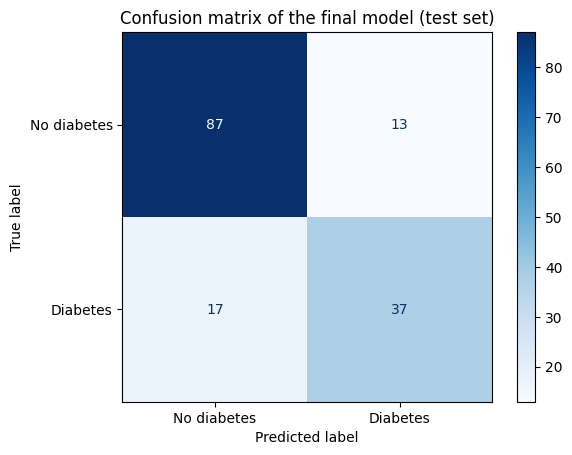

In [17]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=TARGET_NAMES, cmap='Blues')
plt.title('Confusion matrix of the final model (test set)')
plt.savefig('confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

## 8. Feature importance

Because the model is linear and the features are standardised, the weights can be compared directly.
Positive weights push the prediction towards *diabetes*, negative weights away from it.

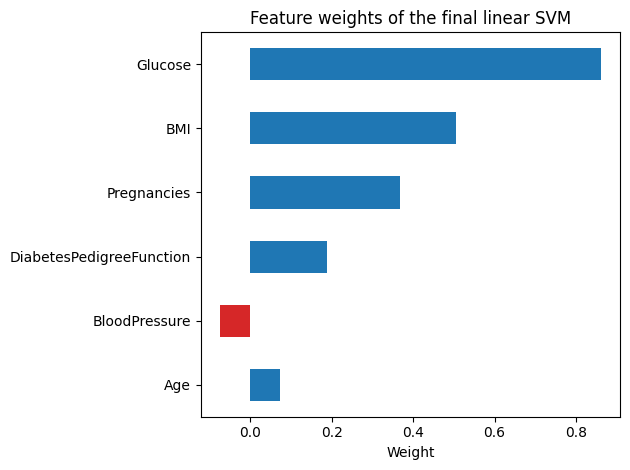

In [18]:
weights = pd.Series(final_model.named_steps['clf'].coef_[0], index=final_feats).sort_values(key=abs)

weights.plot(kind='barh', color=['tab:red' if w < 0 else 'tab:blue' for w in weights])
plt.title('Feature weights of the final linear SVM')
plt.xlabel('Weight')
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

- **Glucose** has by far the strongest influence, as expected for a diabetes test.
- **BMI** is a well-known risk factor.
- **Number of pregnancies** also contributes, consistent with gestational diabetes raising later risk.

Small or negative weights should not be read as protective effects. They reflect noisy features and correlations between features (for example, age and number of pregnancies carry much of the same information).

## Conclusion

- Impossible zero values were treated as missing and data leakage was removed.
- Balanced class weights raised the recall for diabetic patients substantially.
- More complex models did not improve results, so the simple, interpretable linear SVM was kept.
- The final model uses six routinely available features.

*Not a medical device and not intended for clinical use.*